<a href="https://colab.research.google.com/github/contactvarun2002/Cloud-ERP/blob/main/Cloud_ERP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CLOUD ERP — STEP 1: DATA PREPARATION
# Copy this entire block into one Google Colab code cell.
# ============================================================

import csv
import gzip
import json
import re
from collections import defaultdict
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
from zipfile import BadZipFile, ZipFile

import pandas as pd
from google.colab import drive
from sklearn.model_selection import train_test_split


# 1. Google Drive paths

DRIVE = Path("/content/drive/MyDrive")
if not DRIVE.is_dir():
    drive.mount("/content/drive")

DATA = DRIVE / "Cloud ERP"
SAP_ARCHIVE = DATA / "archive (3)"
IBM_ARCHIVE = DATA / "archive (4)"
CLARKNET_LOGS = [
    DATA / "clarknet_access_log_Aug28.gz",
    DATA / "clarknet_access_log_Sep4.gz",
]
OUTPUT = DRIVE / "Cloud_ERP_Fresh_Project" / "Step1_Preprocessed"

SEED = 42
MIN_SAP_CLASS_SIZE = 20


# 2. Shared CSV and splitting functions

def has_columns(stream, required):
    line = stream.readline(65536).decode("utf-8-sig", errors="replace")
    columns = next(csv.reader([line]), [])
    return required <= {column.strip().upper() for column in columns}


def read_dataset(base, required, **read_options):
    matches = []

    if base.is_dir():
        for path in sorted(base.rglob("*")):
            if not path.is_file() or path.suffix.lower() != ".csv":
                continue
            with path.open("rb") as stream:
                if has_columns(stream, required):
                    matches.append(path)

    if len(matches) > 1:
        raise ValueError(f"Multiple matching CSVs in {base}: {matches}")

    if matches:
        source = str(matches[0])
        frame = pd.read_csv(matches[0], **read_options)
    else:
        zip_path = base if base.is_file() else base.with_suffix(".zip")
        if not zip_path.is_file():
            raise FileNotFoundError(
                f"No CSV with columns {sorted(required)} found in {base} or {zip_path}."
            )

        with ZipFile(zip_path) as archive:
            members = []
            for member in archive.infolist():
                if member.is_dir() or not member.filename.lower().endswith(".csv"):
                    continue
                with archive.open(member) as stream:
                    if has_columns(stream, required):
                        members.append(member)

            if len(members) != 1:
                raise ValueError(
                    f"Expected one matching CSV in {zip_path}. "
                    f"Found {[member.filename for member in members]}."
                )

            source = f"{zip_path} [{members[0].filename}]"
            with archive.open(members[0]) as stream:
                frame = pd.read_csv(stream, **read_options)

    if frame.empty:
        raise ValueError(f"Empty dataset: {source}")

    frame.columns = frame.columns.str.strip().str.lstrip("\ufeff")
    print(f"Using {source}", flush=True)
    return frame, source


def make_text(frame, fields, context):
    if not fields:
        return [context] * len(frame)

    values = frame[fields].astype(object)
    values = values.where(values.notna(), "unknown")
    return [
        context + ". " + "; ".join(
            f"{field}={value}" for field, value in zip(fields, row)
        )
        for row in values.itertuples(index=False, name=None)
    ]


def stratified_splits(frame):
    train, holdout = train_test_split(
        frame, test_size=0.20, random_state=SEED, stratify=frame["target"]
    )
    validation, test = train_test_split(
        holdout, test_size=0.50, random_state=SEED, stratify=holdout["target"]
    )
    splits = {"train": train, "validation": validation, "test": test}

    expected_labels = set(frame["target"])
    if any(set(split["target"]) != expected_labels for split in splits.values()):
        raise ValueError("Every class must have records in all three splits.")

    return splits


# 3. SAP sales document classification

def prepare_sap(folder):
    raw, source = read_dataset(SAP_ARCHIVE, {"VBELN", "AUART"}, dtype="string")
    raw.columns = raw.columns.str.upper()

    keys = ["MANDT", "VBELN"] if "MANDT" in raw else ["VBELN"]
    numeric = ["NETWR"] if "NETWR" in raw else []
    categorical = [
        name for name in ["WAERK", "VKORG", "VTWEG", "SPART", "VKBUR", "VKGRP"]
        if name in raw
    ]
    date_columns = ["ERDAT"] if "ERDAT" in raw else []

    fields = keys + ["AUART"] + numeric + categorical + date_columns
    data = raw[fields].apply(lambda col: col.str.strip().replace("", pd.NA))
    data["AUART"] = data["AUART"].str.upper()

    valid = data.dropna(subset=keys + ["AUART"])
    unique_rows = valid.drop_duplicates()
    conflicting = unique_rows.duplicated(keys, keep=False)
    conflicts = unique_rows.loc[conflicting].copy()

    if not conflicts.empty:
        conflicts.insert(0, "source_record_number", conflicts.index + 1)
        conflicts.to_csv(folder / "VBAK_Conflicting_Documents.csv", index=False)
        print(f"SAP: saved {len(conflicts):,} conflicting rows for review.")

    data = unique_rows.loc[~conflicting].copy()
    counts = data["AUART"].value_counts()
    supported = counts[counts >= MIN_SAP_CLASS_SIZE]

    if len(supported) < 2:
        raise ValueError(
            f"SAP needs at least two AUART classes with {MIN_SAP_CLASS_SIZE} "
            f"records each. Found {counts.to_dict()}."
        )

    data = data[data["AUART"].isin(supported.index)].copy()

    if date_columns:
        compact = pd.to_datetime(data["ERDAT"], format="%Y%m%d", errors="coerce")
        iso = pd.to_datetime(data["ERDAT"], format="%Y-%m-%d", errors="coerce")
        created = compact.fillna(iso)
        if created.notna().any():
            data["created_month"] = created.dt.month
            data["created_weekday"] = created.dt.dayofweek
            numeric.extend(["created_month", "created_weekday"])

    for field in numeric:
        data[field] = pd.to_numeric(data[field], errors="coerce")

    features = numeric + categorical
    if not features:
        raise ValueError("SAP VBAK needs predictor columns such as NETWR, VKORG, or ERDAT.")

    data["record_id"] = data[keys].agg("/".join, axis=1)
    data["target"] = data["AUART"]
    data["semantic_text"] = make_text(data, features, "SAP sales document")

    columns = ["record_id", *features, "semantic_text", "target"]
    return stratified_splits(data[columns]), {
        "task": "classification",
        "target_definition": "SAP VBAK sales document type (AUART)",
        "source": source,
        "source_rows": len(raw),
        "missing_key_or_label_rows": len(raw) - len(valid),
        "duplicate_model_rows_removed": len(valid) - len(unique_rows),
        "conflicting_rows_excluded": len(conflicts),
        "conflicting_document_keys_excluded": len(conflicts.drop_duplicates(keys)),
        "excluded_rare_classes": counts[counts < MIN_SAP_CLASS_SIZE].to_dict(),
        "numeric_features": numeric,
        "categorical_features": categorical,
    }


# 4. IBM HR attrition classification

def prepare_ibm(_folder):
    raw, source = read_dataset(IBM_ARCHIVE, {"ATTRITION", "EMPLOYEENUMBER"})
    canonical = {"ATTRITION": "Attrition", "EMPLOYEENUMBER": "EmployeeNumber"}
    data = raw.rename(columns=lambda name: canonical.get(name.upper(), name))
    data = data.drop_duplicates().reset_index(drop=True)

    labels = data.pop("Attrition").astype("string").str.strip().str.lower()
    ids = data.pop("EmployeeNumber").astype("string").str.strip()

    if labels.isna().any() or set(labels) != {"yes", "no"}:
        raise ValueError("IBM Attrition must contain Yes and No with no missing labels.")

    if ids.isna().any() or ids.eq("").any() or ids.duplicated().any():
        raise ValueError("IBM EmployeeNumber must be present and unique after deduplication.")

    data = data.drop(columns=["EmployeeCount", "StandardHours", "Over18"], errors="ignore")
    categorical = data.select_dtypes(exclude="number").columns.tolist()
    numeric = [name for name in data if name not in categorical]

    data.insert(0, "record_id", ids)
    data["semantic_text"] = make_text(data, categorical, "IBM employee profile")
    data["target"] = labels.map({"no": 0, "yes": 1}).astype(int)

    return stratified_splits(data), {
        "task": "classification",
        "target_definition": "Employee attrition, No=0 and Yes=1",
        "source": source,
        "source_rows": len(raw),
        "duplicate_rows_removed": len(raw) - len(data),
        "numeric_features": numeric,
        "categorical_features": categorical,
    }


# 5. ClarkNet next-minute workload forecasting

LOG_PATTERN = re.compile(
    rb'^\S+.*?\[([^\]]+)\]\s+"(.*)"\s+(\d{3})\s+(\d+|-)(?:\s|$)'
)
APACHE_TIME = re.compile(
    rb"^(\d{2}/[A-Za-z]{3}/\d{4}:\d{2}:\d{2}):\d{2} ([+-]\d{4})$"
)
ARCHIVE_TIME = re.compile(
    rb"^(?:[A-Za-z]{3} )?([A-Za-z]{3}\s+\d{1,2} \d{2}:\d{2}):\d{2} (\d{4})$"
)


@lru_cache(maxsize=4096)
def parse_minute(stamp):
    apache = APACHE_TIME.fullmatch(stamp)
    if apache:
        value = b" ".join(apache.groups()).decode("ascii")
        parsed = datetime.strptime(value, "%d/%b/%Y:%H:%M %z")
    else:
        archive = ARCHIVE_TIME.fullmatch(stamp)
        if not archive:
            raise ValueError("Unknown timestamp format.")
        value = (b" ".join(archive.groups()) + b" -0400").decode("ascii")
        parsed = datetime.strptime(value, "%b %d %H:%M %Y %z")

    return parsed.astimezone(timezone.utc)


def prepare_clarknet(folder):
    buckets = defaultdict(lambda: [0, 0, 0, 0])
    file_stats = {}
    previous_last = None

    for path in CLARKNET_LOGS:
        print(f"Reading {path}", flush=True)
        parsed = skipped = 0
        first = last = None

        with gzip.open(path, "rb") as stream:
            for line in stream:
                match = LOG_PATTERN.match(line)
                if match is None:
                    skipped += 1
                    continue

                try:
                    minute = parse_minute(match[1])
                except ValueError:
                    skipped += 1
                    continue

                first = minute if first is None or minute < first else first
                last = minute if last is None or minute > last else last

                status = int(match[3])
                values = buckets[minute]
                values[0] += 1
                values[1] += int(match[4]) if match[4] != b"-" else 0
                values[2] += 400 <= status < 500
                values[3] += 500 <= status < 600
                parsed += 1

        if not parsed:
            raise ValueError(f"No valid requests parsed from {path.name}.")
        if previous_last is not None and first <= previous_last:
            raise ValueError(f"ClarkNet logs overlap or are out of order at {path.name}.")

        previous_last = last
        file_stats[path.name] = {"parsed": parsed, "skipped": skipped}
        print(f"  Parsed {parsed:,} requests, skipped {skipped:,} lines.", flush=True)

    current = ["requests", "response_bytes", "http_4xx", "http_5xx"]
    minutes = pd.DataFrame.from_dict(buckets, orient="index", columns=current).sort_index()
    minutes.index.name = "window_start_utc"
    minutes = minutes.asfreq("min", fill_value=0)

    observed = int(minutes["requests"].sum())
    archive_count = 3_328_587
    if observed != archive_count:
        print(f"ClarkNet archive count difference: {observed - archive_count:+,}.")

    data = minutes.copy()
    data["requests_lag_1"] = data["requests"].shift(1)
    data["requests_lag_5"] = data["requests"].shift(5)
    data["requests_mean_5"] = data["requests"].rolling(5).mean()
    local_time = data.index.tz_convert("Etc/GMT+4")
    data["hour_local"] = local_time.hour
    data["weekday_local"] = local_time.dayofweek

    # Features come from the completed minute and its history.
    # The label is the request count in the following minute.
    data["target"] = data["requests"].shift(-1)
    data = data.dropna(subset=["requests_lag_5", "target"]).copy()
    data["target"] = data["target"].astype(int)
    data["target_window_utc"] = data.index + pd.Timedelta(minutes=1)
    data["semantic_text"] = make_text(data, current, "Completed ClarkNet traffic minute")
    data = data.reset_index()

    if len(data) < 10:
        raise ValueError("Too few usable ClarkNet windows for an 80/10/10 split.")

    cut1 = int(len(data) * 0.80)
    cut2 = int(len(data) * 0.90)
    splits = {
        "train": data.iloc[:cut1],
        "validation": data.iloc[cut1:cut2],
        "test": data.iloc[cut2:],
    }
    minutes.to_csv(folder / "observed_minute_counts.csv")

    return splits, {
        "task": "regression",
        "target_definition": "Request count in the next one-minute window",
        "time_fields": ["window_start_utc", "target_window_utc"],
        "numeric_features": current + [
            "requests_lag_1", "requests_lag_5", "requests_mean_5",
            "hour_local", "weekday_local",
        ],
        "categorical_features": [],
        "raw_file_stats": file_stats,
        "parsed_raw_requests": observed,
        "archive_reported_requests": archive_count,
        "raw_request_difference": observed - archive_count,
    }


# 6. Run Step 1 and save the split CSVs and summary

run = OUTPUT / datetime.now(timezone.utc).strftime("Run_%Y%m%d_%H%M%S_%f")
run.mkdir(parents=True, exist_ok=False)
results = {}

for name, prepare in [
    ("SAP", prepare_sap),
    ("IBM_HR", prepare_ibm),
    ("ClarkNet", prepare_clarknet),
]:
    folder = run / name
    folder.mkdir()

    try:
        splits, metadata = prepare(folder)
        metadata["splits"] = {}

        for split_name, frame in splits.items():
            frame.to_csv(folder / f"{split_name}.csv", index=False)
            details = {"rows": len(frame)}

            if metadata["task"] == "classification":
                details["class_counts"] = {
                    str(label): int(count)
                    for label, count in frame["target"].value_counts().items()
                }
            else:
                details["first_target_window_utc"] = frame["target_window_utc"].iloc[0].isoformat()
                details["last_target_window_utc"] = frame["target_window_utc"].iloc[-1].isoformat()

            metadata["splits"][split_name] = details

        (folder / "metadata.json").write_text(
            json.dumps(metadata, indent=2), encoding="utf-8"
        )
        results[name] = {"status": "ready", **metadata}

        counts = ", ".join(f"{split}={len(frame):,}" for split, frame in splits.items())
        print(f"{name}: {counts}", flush=True)

    except (OSError, ValueError, EOFError, BadZipFile, csv.Error) as error:
        results[name] = {"status": "failed", "error": str(error)}
        print(f"{name}: {error}", flush=True)

(run / "Step1_Summary.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"\nOutput folder: {run}", flush=True)

failed = [name for name, result in results.items() if result["status"] != "ready"]
if failed:
    raise RuntimeError("STEP 1 INCOMPLETE. Check the messages for: " + ", ".join(failed))

print("STEP 1 COMPLETE")

Using /content/drive/MyDrive/Cloud ERP/archive (3)/vbak.csv
SAP: saved 2 conflicting rows for review.
SAP: train=28,144, validation=3,518, test=3,518
Using /content/drive/MyDrive/Cloud ERP/archive (4)/WA_Fn-UseC_-HR-Employee-Attrition.csv
IBM_HR: train=1,176, validation=147, test=147
Reading /content/drive/MyDrive/Cloud ERP/clarknet_access_log_Aug28.gz
  Parsed 1,654,882 requests, skipped 0 lines.
Reading /content/drive/MyDrive/Cloud ERP/clarknet_access_log_Sep4.gz
  Parsed 1,673,750 requests, skipped 0 lines.
ClarkNet archive count difference: +45.
ClarkNet: train=16,123, validation=2,015, test=2,016

Output folder: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step1_Preprocessed/Run_20261107_143852_076129
STEP 1 COMPLETE


In [ ]:
# ============================================================
# CLOUD ERP STEP 2 — FEATURE EXTRACTION AND QXNN TRAINING
# Full replacement cell with the SentencePiece compatibility fix.
# ============================================================

import os
import subprocess
import sys
from pathlib import Path

import torch
from google.colab import drive, userdata

# 1. Runtime and paths

if not torch.cuda.is_available():
    raise RuntimeError("Enable a GPU under Runtime → Change runtime type.")

drive_root = Path("/content/drive/MyDrive")
if not drive_root.is_dir():
    drive.mount("/content/drive")

project = drive_root / "Cloud_ERP_Fresh_Project"

# Leave blank to use the newest completed Step 1 run.
STEP1_RUN = ""

if not STEP1_RUN and not (project / "Step1_Preprocessed").is_dir():
    raise FileNotFoundError(f"Step 1 output folder is missing under {project}.")

try:
    token = (userdata.get("HF_TOKEN") or "").strip()
except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
    raise RuntimeError(
        "Add HF_TOKEN under Colab Secrets and enable Notebook access."
    ) from None

if not token:
    raise RuntimeError("HF_TOKEN is empty. Check the value in Colab Secrets.")

# 2. Isolated packages and SentencePiece fix

deps = Path("/content/cloud_erp_fresh_step2_deps")
package_marker = deps / ".installed-v1"

if not package_marker.is_file():
    print("Installing Step 2 model packages...", flush=True)
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q", "--upgrade",
            "--target", str(deps), "--no-deps",
            "transformers==4.57.6",
            "huggingface-hub==0.36.2",
            "tokenizers>=0.22,<=0.23.0",
            "safetensors>=0.4.3",
            "hf-xet>=1.1.3,<2",
            "accelerate==1.12.0",
            "bitsandbytes==0.49.2",
        ],
        check=True,
    )
    package_marker.touch()

# Put the pinned package ahead of any previously installed SentencePiece.
fix_dir = Path("/content/cloud_erp_sentencepiece_fix")
fix_marker = fix_dir / ".sentencepiece-0.2.1"

if not fix_marker.is_file():
    print("Installing compatible SentencePiece 0.2.1...", flush=True)
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q", "--upgrade",
            "--target", str(fix_dir), "--no-deps", "--only-binary=:all:",
            "sentencepiece==0.2.1",
        ],
        check=True,
    )
    fix_marker.touch()

env = os.environ.copy()
env["HF_TOKEN"] = token
env["ERP_PROJECT"] = str(project)
env["ERP_STEP1_RUN"] = STEP1_RUN
env["PYTHONPATH"] = os.pathsep.join(
    part for part in (str(fix_dir), str(deps), env.get("PYTHONPATH", "")) if part
)

subprocess.run(
    [
        sys.executable, "-c",
        "import sentencepiece; "
        "from sentencepiece import sentencepiece_model_pb2; "
        "assert sentencepiece.__version__ == '0.2.1'; "
        "print('Tokenizer dependency OK. SentencePiece:', sentencepiece.__version__)",
    ],
    env=env,
    check=True,
)

# 3. Complete training code. Colab creates the worker file automatically.

worker_code = r'''
import gc
import hashlib
import json
import os
import random
import shutil
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import joblib
import numpy as np
import pandas as pd
import torch
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

PROJECT = Path(os.environ["ERP_PROJECT"])
DATASETS = ("SAP", "IBM_HR", "ClarkNet")
SPLITS = ("train", "validation", "test")

ENCODERS = (
    ("Llama", "TinyLlama/TinyLlama-1.1B-Chat-v1.0", False),
    ("Mistral", "mistralai/Mistral-7B-v0.3", True),
    ("Qwen", "Qwen/Qwen2.5-0.5B", False),
    ("Gemma", "google/gemma-2-2b", False),
)

DEVICE = torch.device("cuda:0")
SEED = 42
MAX_TOKENS = 128
EMBED_BATCH = 16
CACHE_CHUNK = 512
TRAIN_BATCH = 32
MAX_EPOCHS = 30
PATIENCE = 8
QUBITS = 8
CIRCUIT_DEPTH = 4
FUSION_WIDTH = 768


def write_json(path, value):
    path.write_text(json.dumps(value, indent=2), encoding="utf-8")


def find_step1_run():
    override = os.environ.get("ERP_STEP1_RUN", "").strip()
    candidates = (
        [Path(override)] if override else
        sorted((PROJECT / "Step1_Preprocessed").glob("Run_*"), reverse=True)
    )

    for run in candidates:
        summary = run / "Step1_Summary.json"
        if summary.is_file():
            status = json.loads(summary.read_text(encoding="utf-8"))
            if all(status.get(name, {}).get("status") == "ready" for name in DATASETS):
                return run

    raise FileNotFoundError("No completed Step 1 run found. Check STEP1_RUN and Step1_Summary.json.")


def load_dataset(run, name):
    folder = run / name
    meta = json.loads((folder / "metadata.json").read_text(encoding="utf-8"))
    text_cols = ["record_id", "semantic_text", *meta["categorical_features"]]

    if meta["task"] == "classification":
        text_cols.append("target")

    frames = {}
    for split in SPLITS:
        frame = pd.read_csv(
            folder / f"{split}.csv",
            dtype={col: "string" for col in text_cols},
            keep_default_na=False,
        )
        if frame.empty or len(frame) != meta["splits"][split]["rows"]:
            raise ValueError(f"{name}/{split}: row count differs from Step 1 metadata.")
        if frame["semantic_text"].str.strip().eq("").any():
            raise ValueError(f"{name}/{split}: missing semantic text.")
        frames[split] = frame

    texts = pd.concat([frames[split]["semantic_text"] for split in SPLITS], ignore_index=True)
    codes, unique = pd.factorize(texts, sort=False)
    indices = {}
    offset = 0
    for split in SPLITS:
        end = offset + len(frames[split])
        indices[split] = codes[offset:end]
        offset = end

    return {"meta": meta, "frames": frames, "texts": unique.tolist(), "indices": indices}


def prepare_tabular(meta, frames):
    numeric = meta["numeric_features"]
    categorical = meta["categorical_features"]
    clean = {}

    for split, frame in frames.items():
        table = frame[numeric + categorical].copy()
        for column in numeric:
            table[column] = pd.to_numeric(table[column], errors="coerce").replace(
                [np.inf, -np.inf], np.nan
            )
        for column in categorical:
            table[column] = table[column].replace("", "__MISSING__").astype(str)
        clean[split] = table

    preprocessor = ColumnTransformer([
        ("numeric", make_pipeline(
            SimpleImputer(strategy="median", keep_empty_features=True),
            MinMaxScaler(),
        ), numeric),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore", sparse_output=False
        ), categorical),
    ])

    preprocessor.fit(clean["train"])
    arrays = {
        split: preprocessor.transform(clean[split]).astype(np.float32)
        for split in SPLITS
    }
    return preprocessor, arrays


def load_encoder(model_id, use_4bit):
    from transformers import AutoModel, AutoTokenizer, BitsAndBytesConfig

    token = os.environ["HF_TOKEN"]
    dtype = torch.float16
    options = {
        "token": token,
        "use_safetensors": True,
        "low_cpu_mem_usage": True,
    }

    if model_id == "google/gemma-2-2b":
        dtype = (
            torch.bfloat16
            if torch.cuda.is_bf16_supported(including_emulation=False)
            else torch.float32
        )
        options["attn_implementation"] = "eager"

    if use_4bit:
        options["device_map"] = {"": 0}
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=dtype,
            bnb_4bit_use_double_quant=True,
        )

    tokenizer = AutoTokenizer.from_pretrained(model_id, token=token)
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    model = AutoModel.from_pretrained(model_id, torch_dtype=dtype, **options)
    if not use_4bit:
        model.to(DEVICE)

    return tokenizer, model.eval()


@torch.inference_mode()
def encode_chunk(texts, tokenizer, model):
    blocks = []
    for start in range(0, len(texts), EMBED_BATCH):
        batch = tokenizer(
            texts[start:start + EMBED_BATCH],
            padding=True, truncation=True,
            max_length=MAX_TOKENS, return_tensors="pt",
        ).to(DEVICE)
        hidden = model(**batch, use_cache=False).last_hidden_state.float()
        mask = batch["attention_mask"].unsqueeze(-1)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        pooled = nn.functional.normalize(pooled, dim=-1)
        if not torch.isfinite(pooled).all():
            raise FloatingPointError("A text encoder produced nonfinite embeddings.")
        blocks.append(pooled.cpu().numpy().astype(np.float16))

    return np.concatenate(blocks)


def build_embedding_cache(corpus, cache_root):
    cache = {}
    for family, model_id, use_4bit in ENCODERS:
        tokenizer = model = None

        try:
            for dataset, entry in corpus.items():
                texts = entry["texts"]

                # Keep the same cache fingerprint as the previous Step 2 cell.
                descriptor = [
                    model_id, use_4bit, MAX_TOKENS, CACHE_CHUNK, "mean_l2_v1", texts
                ]
                digest = hashlib.sha256(
                    json.dumps(descriptor, ensure_ascii=False).encode("utf-8")
                ).hexdigest()[:24]

                folder = cache_root / family / dataset / digest
                folder.mkdir(parents=True, exist_ok=True)
                parts = []

                for start in range(0, len(texts), CACHE_CHUNK):
                    end = min(start + CACHE_CHUNK, len(texts))
                    path = folder / f"{start:08d}.npy"
                    if not path.is_file():
                        if model is None:
                            print(f"Loading {model_id}...", flush=True)
                            tokenizer, model = load_encoder(model_id, use_4bit)
                        array = encode_chunk(texts[start:end], tokenizer, model)
                        temporary = folder / f".{uuid4().hex}.tmp"
                        try:
                            with temporary.open("wb") as handle:
                                np.save(handle, array, allow_pickle=False)
                            temporary.replace(path)
                        finally:
                            temporary.unlink(missing_ok=True)
                        print(f"{family}/{dataset}: {end:,}/{len(texts):,}", flush=True)
                    parts.append(path)

                cache[dataset, family] = parts
                print(f"{family}/{dataset}: embeddings ready", flush=True)
        finally:
            del model, tokenizer
            gc.collect()
            torch.cuda.empty_cache()

    return cache


class QuantumCircuit(nn.Module):
    def __init__(self):
        super().__init__()
        self.angles = nn.Parameter(torch.empty(CIRCUIT_DEPTH, QUBITS, 2))
        nn.init.uniform_(self.angles, -0.1, 0.1)

        basis = torch.arange(2 ** QUBITS)
        bits = [(basis >> (QUBITS - wire - 1)) & 1 for wire in range(QUBITS)]
        self.register_buffer(
            "z_signs", torch.stack([1 - 2 * bit for bit in bits], dim=1).float()
        )

        ring = basis
        for wire, bit in enumerate(bits):
            target = (wire + 1) % QUBITS
            ring = ring[basis ^ (bit << (QUBITS - target - 1))]
        self.register_buffer("ring", ring)

    @staticmethod
    def rotate_y(state, theta, wire):
        view = state.reshape(len(state), 2 ** wire, 2, 2 ** (QUBITS - wire - 1))
        zero, one = view.unbind(dim=2)
        cosine = (theta / 2).cos().reshape(-1, 1, 1)
        sine = (theta / 2).sin().reshape(-1, 1, 1)
        return torch.stack(
            (cosine * zero - sine * one, sine * zero + cosine * one), dim=2
        ).flatten(1)

    def forward(self, inputs):
        encoded = torch.pi * inputs.float().tanh()
        state = torch.zeros(
            (len(inputs), 2 ** QUBITS), device=inputs.device, dtype=torch.complex64
        )
        state[:, 0] = 1

        for wire in range(QUBITS):
            state = self.rotate_y(state, encoded[:, wire], wire)

        for layer in self.angles:
            for wire, theta in enumerate(layer[:, 0]):
                state = self.rotate_y(state, theta, wire)
            phase = self.z_signs @ (-layer[:, 1] / 2)
            state = (state * torch.polar(torch.ones_like(phase), phase)).index_select(1, self.ring)

        probability = state.real.square() + state.imag.square()
        return probability @ self.z_signs


class SeparableBlock(nn.Module):
    def __init__(self, incoming, outgoing):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(incoming, incoming, 3, padding=1, groups=incoming, bias=False),
            nn.Conv2d(incoming, outgoing, 1, bias=False),
            nn.BatchNorm2d(outgoing),
            nn.ReLU(),
            nn.Conv2d(outgoing, outgoing, 3, padding=1, groups=outgoing, bias=False),
            nn.Conv2d(outgoing, outgoing, 1, bias=False),
            nn.BatchNorm2d(outgoing),
        )
        self.skip = nn.Conv2d(incoming, outgoing, 1, bias=False)

    def forward(self, x):
        return (self.main(x) + self.skip(x)).relu()


class ERPXception(nn.Module):
    def __init__(self, semantic_dims, tabular_dim, outputs, quantum):
        super().__init__()
        self.projections = nn.ModuleList(
            nn.Sequential(nn.Linear(width, FUSION_WIDTH), nn.LayerNorm(FUSION_WIDTH))
            for width in semantic_dims
        )
        self.fusion_weights = nn.Parameter(torch.zeros(len(semantic_dims)))
        self.tabular = nn.Linear(tabular_dim, FUSION_WIDTH)
        self.backbone = nn.Sequential(
            nn.Conv2d(2, 24, 3, padding=1, bias=False),
            nn.BatchNorm2d(24),
            nn.ReLU(),
            SeparableBlock(24, 32),
            nn.MaxPool2d(2),
            SeparableBlock(32, 48),
            nn.MaxPool2d(2),
            SeparableBlock(48, 64),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, QUBITS),
        )
        self.bottleneck = (
            QuantumCircuit() if quantum else nn.Sequential(nn.Linear(QUBITS, QUBITS), nn.Tanh())
        )
        self.head = nn.Linear(QUBITS, outputs)

    def forward(self, tabular, *embeddings):
        projected = torch.stack([
            layer(embedding.float())
            for layer, embedding in zip(self.projections, embeddings)
        ], dim=1)
        semantic = (projected * self.fusion_weights.softmax(dim=0)[None, :, None]).sum(dim=1)
        grid = torch.stack((semantic, self.tabular(tabular)), dim=1).reshape(-1, 2, 24, 32)
        return self.head(self.bottleneck(self.backbone(grid)))


def prepare_targets(task, frames):
    if task == "classification":
        labels = sorted(set(frames["train"]["target"]))
        lookup = {label: index for index, label in enumerate(labels)}
        targets = {}
        for split in ("train", "validation"):
            encoded = frames[split]["target"].map(lookup)
            if encoded.isna().any() or "" in lookup or len(labels) < 2:
                raise ValueError(f"Missing or unknown class labels in {split}.")
            targets[split] = encoded.to_numpy(dtype=np.int64)
        return targets, {"classes": labels, "outputs": len(labels), "metric": "macro_f1"}

    raw = {
        split: frames[split]["target"].to_numpy(dtype=np.float32)
        for split in ("train", "validation")
    }
    if any((~np.isfinite(values) | (values < 0)).any() for values in raw.values()):
        raise ValueError("Workload targets must be finite and nonnegative.")
    mean = float(raw["train"].mean())
    scale = float(raw["train"].std()) or 1.0
    targets = {split: (values - mean) / scale for split, values in raw.items()}
    return targets, {
        "outputs": 1, "target_mean": mean, "target_scale": scale, "metric": "mae_requests",
    }


def run_epoch(model, loader, loss_fn, classification, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    truth, predictions = [], []

    with torch.set_grad_enabled(training):
        for batch in loader:
            *inputs, target = [tensor.to(DEVICE, non_blocking=True) for tensor in batch]
            output = model(*inputs)
            if not classification:
                output = output[:, 0]

            loss = loss_fn(output, target)
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite training or validation loss.")

            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            else:
                predicted = output.argmax(dim=1) if classification else output
                predictions.append(predicted.cpu().numpy())
                truth.append(target.cpu().numpy())

            total_loss += loss.item() * len(target)

    evaluation = (np.concatenate(truth), np.concatenate(predictions)) if not training else None
    return total_loss / len(loader.dataset), evaluation


def train_variant(folder, variant, config, features, targets):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    classification = config["task"] == "classification"

    model = ERPXception(
        config["semantic_dims"], config["tabular_dim"], config["outputs"],
        quantum=variant == "QXNN",
    ).to(DEVICE)

    if classification:
        counts = np.bincount(targets["train"], minlength=config["outputs"])
        weights = torch.tensor(
            np.sqrt(counts.max() / counts), dtype=torch.float32, device=DEVICE
        )
        loss_fn = nn.CrossEntropyLoss(weight=weights)
    else:
        loss_fn = nn.MSELoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.5, patience=3
    )

    loaders = {}
    for split in ("train", "validation"):
        tensors = [torch.from_numpy(x) for x in [*features[split], targets[split]]]
        loaders[split] = DataLoader(
            TensorDataset(*tensors),
            batch_size=TRAIN_BATCH,
            shuffle=split == "train",
            generator=torch.Generator().manual_seed(SEED),
            pin_memory=True,
        )

    history = []
    best_rank, best_value, best_epoch = -np.inf, None, 0
    checkpoint = folder / f"{variant}_Best.pt"

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, _ = run_epoch(
            model, loaders["train"], loss_fn, classification, optimizer
        )
        val_loss, (truth, predicted) = run_epoch(
            model, loaders["validation"], loss_fn, classification
        )

        if classification:
            value = float(f1_score(
                truth, predicted, labels=np.arange(config["outputs"]),
                average="macro", zero_division=0,
            ))
        else:
            scale, mean = config["target_scale"], config["target_mean"]
            value = float(mean_absolute_error(
                truth * scale + mean, np.maximum(predicted * scale + mean, 0)
            ))

        rank = value if classification else -value
        scheduler.step(-rank)
        history.append({
            "epoch": epoch, "train_loss": train_loss, "validation_loss": val_loss,
            config["metric"]: value,
        })
        print(
            f"{folder.name}/{variant} epoch {epoch:02d} | "
            f"train loss={train_loss:.4f} | {config['metric']}={value:.4f}",
            flush=True,
        )

        if rank > best_rank:
            best_rank, best_value, best_epoch = rank, value, epoch
            temporary = checkpoint.with_suffix(".tmp")
            torch.save({
                "state_dict": model.state_dict(), "config": config, "variant": variant,
            }, temporary)
            temporary.replace(checkpoint)

        if epoch - best_epoch >= PATIENCE:
            break

    pd.DataFrame(history).to_csv(folder / f"{variant}_History.csv", index=False)
    return {
        "dataset": folder.name, "variant": variant, "best_epoch": best_epoch,
        "metric": config["metric"], "validation_score": best_value,
    }


def main():
    step1 = find_step1_run()
    print(f"Using completed Step 1 run: {step1}", flush=True)

    root = PROJECT / "Step2_QXNN"
    corpus = {name: load_dataset(step1, name) for name in DATASETS}
    cache = build_embedding_cache(corpus, root / "Embedding_Cache")

    run = root / datetime.now(timezone.utc).strftime("Run_%Y%m%d_%H%M%S_%f")
    run.mkdir(parents=True, exist_ok=False)
    shutil.copyfile(__file__, run / "Step2_Training_Source.py")
    print(f"Step 2 output folder: {run}", flush=True)

    comparison = []
    for name, entry in corpus.items():
        folder = run / name
        folder.mkdir()
        meta, frames = entry["meta"], entry["frames"]
        preprocessor, tabular = prepare_tabular(meta, frames)
        targets, task_config = prepare_targets(meta["task"], frames)

        features = {split: [tabular[split]] for split in SPLITS}
        dimensions = []

        for family, _, _ in ENCODERS:
            vectors = np.concatenate([
                np.load(path, allow_pickle=False) for path in cache[name, family]
            ])
            if vectors.ndim != 2 or len(vectors) != len(entry["texts"]):
                raise ValueError(f"Embedding cache mismatch for {name}/{family}.")
            dimensions.append(vectors.shape[1])

            for split in SPLITS:
                features[split].append(vectors[entry["indices"][split]])
            del vectors

        order = ["tabular", *[family for family, _, _ in ENCODERS]]
        config = {
            "dataset": name,
            "task": meta["task"],
            "semantic_dims": dimensions,
            "tabular_dim": tabular["train"].shape[1],
            "feature_order": order,
            "model_ids": [model_id for _, model_id, _ in ENCODERS],
            "tabular_feature_names": preprocessor.get_feature_names_out().tolist(),
            **task_config,
        }
        write_json(folder / "Model_Config.json", config)
        joblib.dump(preprocessor, folder / "Tabular_Preprocessor.joblib")

        test = frames["test"]
        id_column = "target_window_utc" if name == "ClarkNet" else "record_id"
        target_dtype = np.float32 if name == "ClarkNet" else str
        np.savez(
            folder / "Test_Inputs.npz",
            **dict(zip(order, features.pop("test"))),
            row_id=test[id_column].to_numpy(dtype=str),
            target_original=test["target"].to_numpy(dtype=target_dtype),
        )

        for variant in ("Classical_Xception", "QXNN"):
            comparison.append(train_variant(folder, variant, config, features, targets))

    table = pd.DataFrame(comparison)
    table.to_csv(run / "Validation_Comparison.csv", index=False)
    write_json(run / "Step2_Summary.json", {
        "status": "ready", "step1_run": str(step1), "results": comparison,
    })

    print(table.to_string(index=False), flush=True)
    print(f"STEP 2 COMPLETE\nOutput folder: {run}", flush=True)


if __name__ == "__main__":
    main()
'''

worker = Path("/content/cloud_erp_fresh_step2_worker.py")
worker.write_text(worker_code, encoding="utf-8")

# Show the worker's actual output if a later operation fails.
with subprocess.Popen(
    [sys.executable, "-u", str(worker)],
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    errors="replace",
) as process:
    for line in process.stdout:
        print(line.replace(token, "[REDACTED]"), end="", flush=True)
    exit_code = process.wait()

if exit_code:
    raise RuntimeError(
        f"Step 2 exited with code {exit_code}. The underlying error is printed above."
    )

Installing compatible SentencePiece 0.2.1...
Using completed Step 1 run: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step1_Preprocessed/Run_20261107_143852_076129
Llama/SAP: embeddings ready
Llama/IBM_HR: embeddings ready
Llama/ClarkNet: embeddings ready
Loading mistralai/Mistral-7B-v0.3...
`torch_dtype` is deprecated! Use `dtype` instead!
I0000 00:00:1794065168.622376   27674 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794065171.161257   27674 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

Fetching 3 files: 100%|██████████| 3/3 [02:45<00:00, 55.24s/it] 

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]/content/cloud_erp_fresh_step2_deps/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_

In [ ]:
# CLOUD ERP — STEP 2 RETRY AND ERROR DIAGNOSIS
# Paste into a new Colab cell below your failed Step 2 cell.

import os
import subprocess
import sys
from collections import deque
from pathlib import Path

from google.colab import userdata

worker = Path("/content/cloud_erp_fresh_step2_worker.py")
deps = Path("/content/cloud_erp_fresh_step2_deps")
project = Path("/content/drive/MyDrive/Cloud_ERP_Fresh_Project")

if not worker.is_file() or not deps.is_dir():
    raise RuntimeError(
        "The Step 2 files are missing from this runtime. "
        "Run your original Step 2 cell once, then come back to this cell."
    )

if not project.is_dir():
    raise FileNotFoundError(
        f"Project folder is unavailable: {project}. Mount Google Drive first."
    )

try:
    token = (userdata.get("HF_TOKEN") or "").strip()
except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
    raise RuntimeError(
        "In Colab Secrets, enable Notebook access for HF_TOKEN."
    ) from None

if not token:
    raise RuntimeError("HF_TOKEN is empty. Check its value in Colab Secrets.")

retry_env = os.environ.copy()
retry_env["HF_TOKEN"] = token
retry_env["ERP_PROJECT"] = str(project)
retry_env["ERP_STEP1_RUN"] = globals().get("STEP1_RUN") or ""
retry_env["PYTHONPATH"] = os.pathsep.join(
    part for part in (str(deps), retry_env.get("PYTHONPATH", "")) if part
)

last_lines = deque(maxlen=30)

print("Starting Step 2. The training script will print its own error below.", flush=True)

with subprocess.Popen(
    [sys.executable, "-u", str(worker)],
    env=retry_env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    errors="replace",
) as process:
    for line in process.stdout:
        safe_line = line.replace(token, "[REDACTED]")
        last_lines.append(safe_line)
        print(safe_line, end="", flush=True)

    exit_code = process.wait()

if exit_code == 0:
    print("\nStep 2 finished. Keep the output folder path printed above.")
else:
    print(f"\nStep 2 stopped with exit code {exit_code}.")
    print("Copy the error details below and send them here:\n")
    print("".join(last_lines), end="")

Starting Step 2. The training script will print its own error below.
Using completed Step 1 run: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step1_Preprocessed/Run_20261107_143852_076129
Llama/SAP: embeddings ready
Llama/IBM_HR: embeddings ready
Llama/ClarkNet: embeddings ready
Loading mistralai/Mistral-7B-v0.3...
Traceback (most recent call last):
  File "/content/cloud_erp_fresh_step2_worker.py", line 568, in <module>
    main()
    ~~~~^^
  File "/content/cloud_erp_fresh_step2_worker.py", line 505, in main
    cache = build_embedding_cache(corpus, root / "Embedding_Cache")
  File "/content/cloud_erp_fresh_step2_worker.py", line 207, in build_embedding_cache
    tokenizer, model = load_encoder(model_id, use_4bit)
                       ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^
  File "/content/cloud_erp_fresh_step2_worker.py", line 148, in load_encoder
    tokenizer = AutoTokenizer.from_pretrained(model_id, token=token)
  File "/content/cloud_erp_fresh_step2_deps/transformers/models/auto/t

Step 1 data: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step1_Preprocessed/Run_20261107_143852_076129
Step 2 checkpoints: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step2_QXNN/Run_20261107_170847_947317
Evaluation device: cuda:0
Step 3 output: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step3_Test_Evaluation/Run_20261112_170817_047877

Processing SAP...
SAP validation selection: {'first_model': 'Classical_Xception', 'second_model': 'ExtraTrees', 'first_weight': 0.25, 'threshold': None, 'metric': 'macro_f1', 'validation_score': 0.5999733087947295}


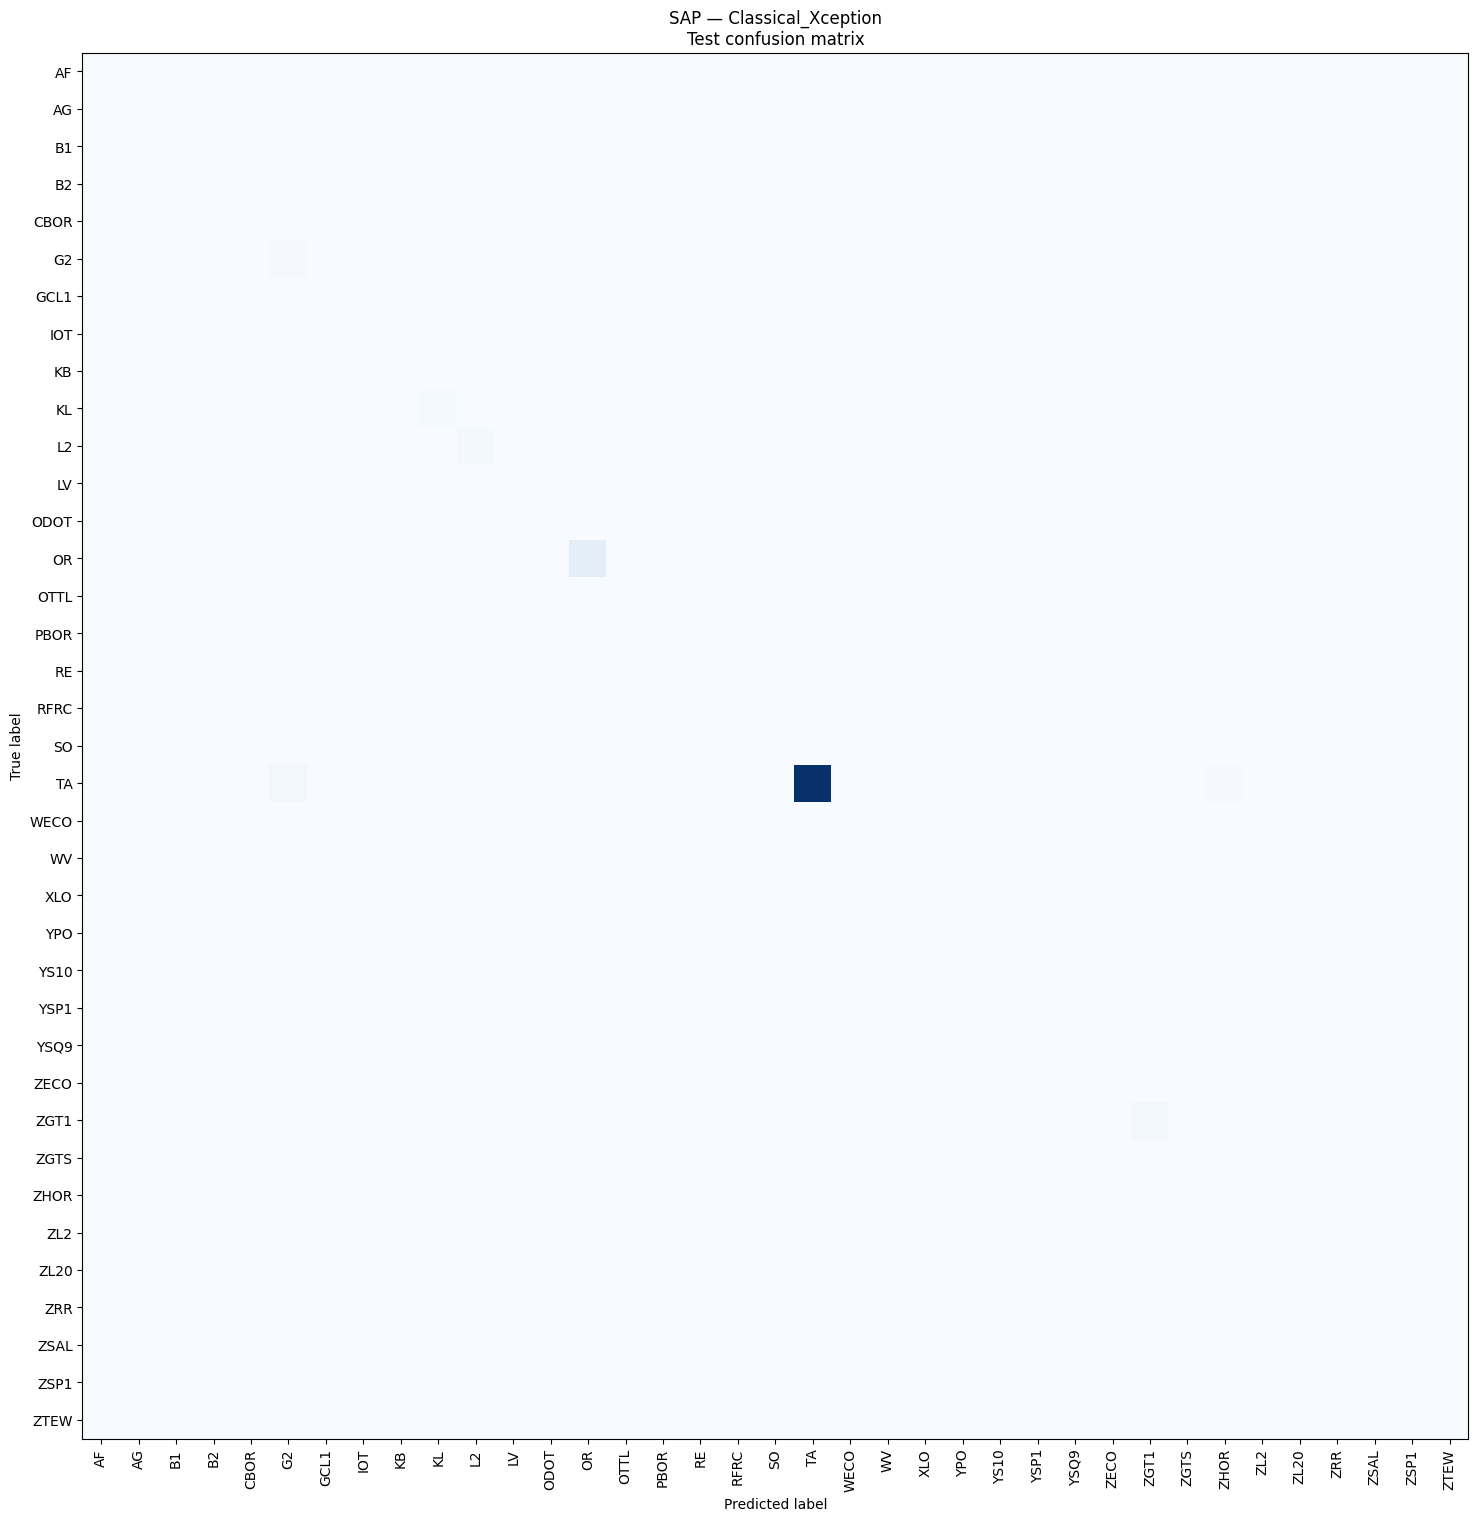

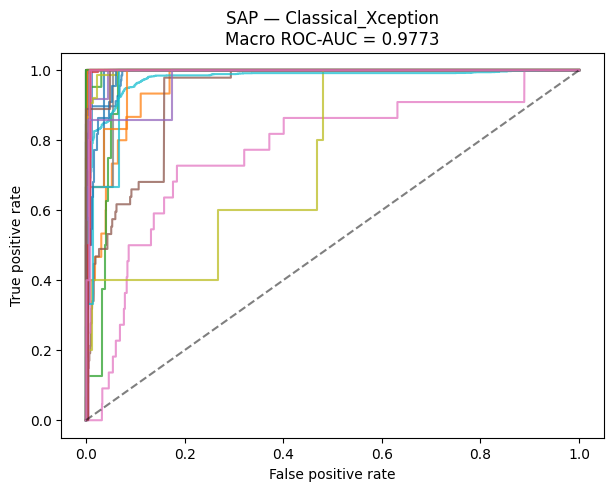

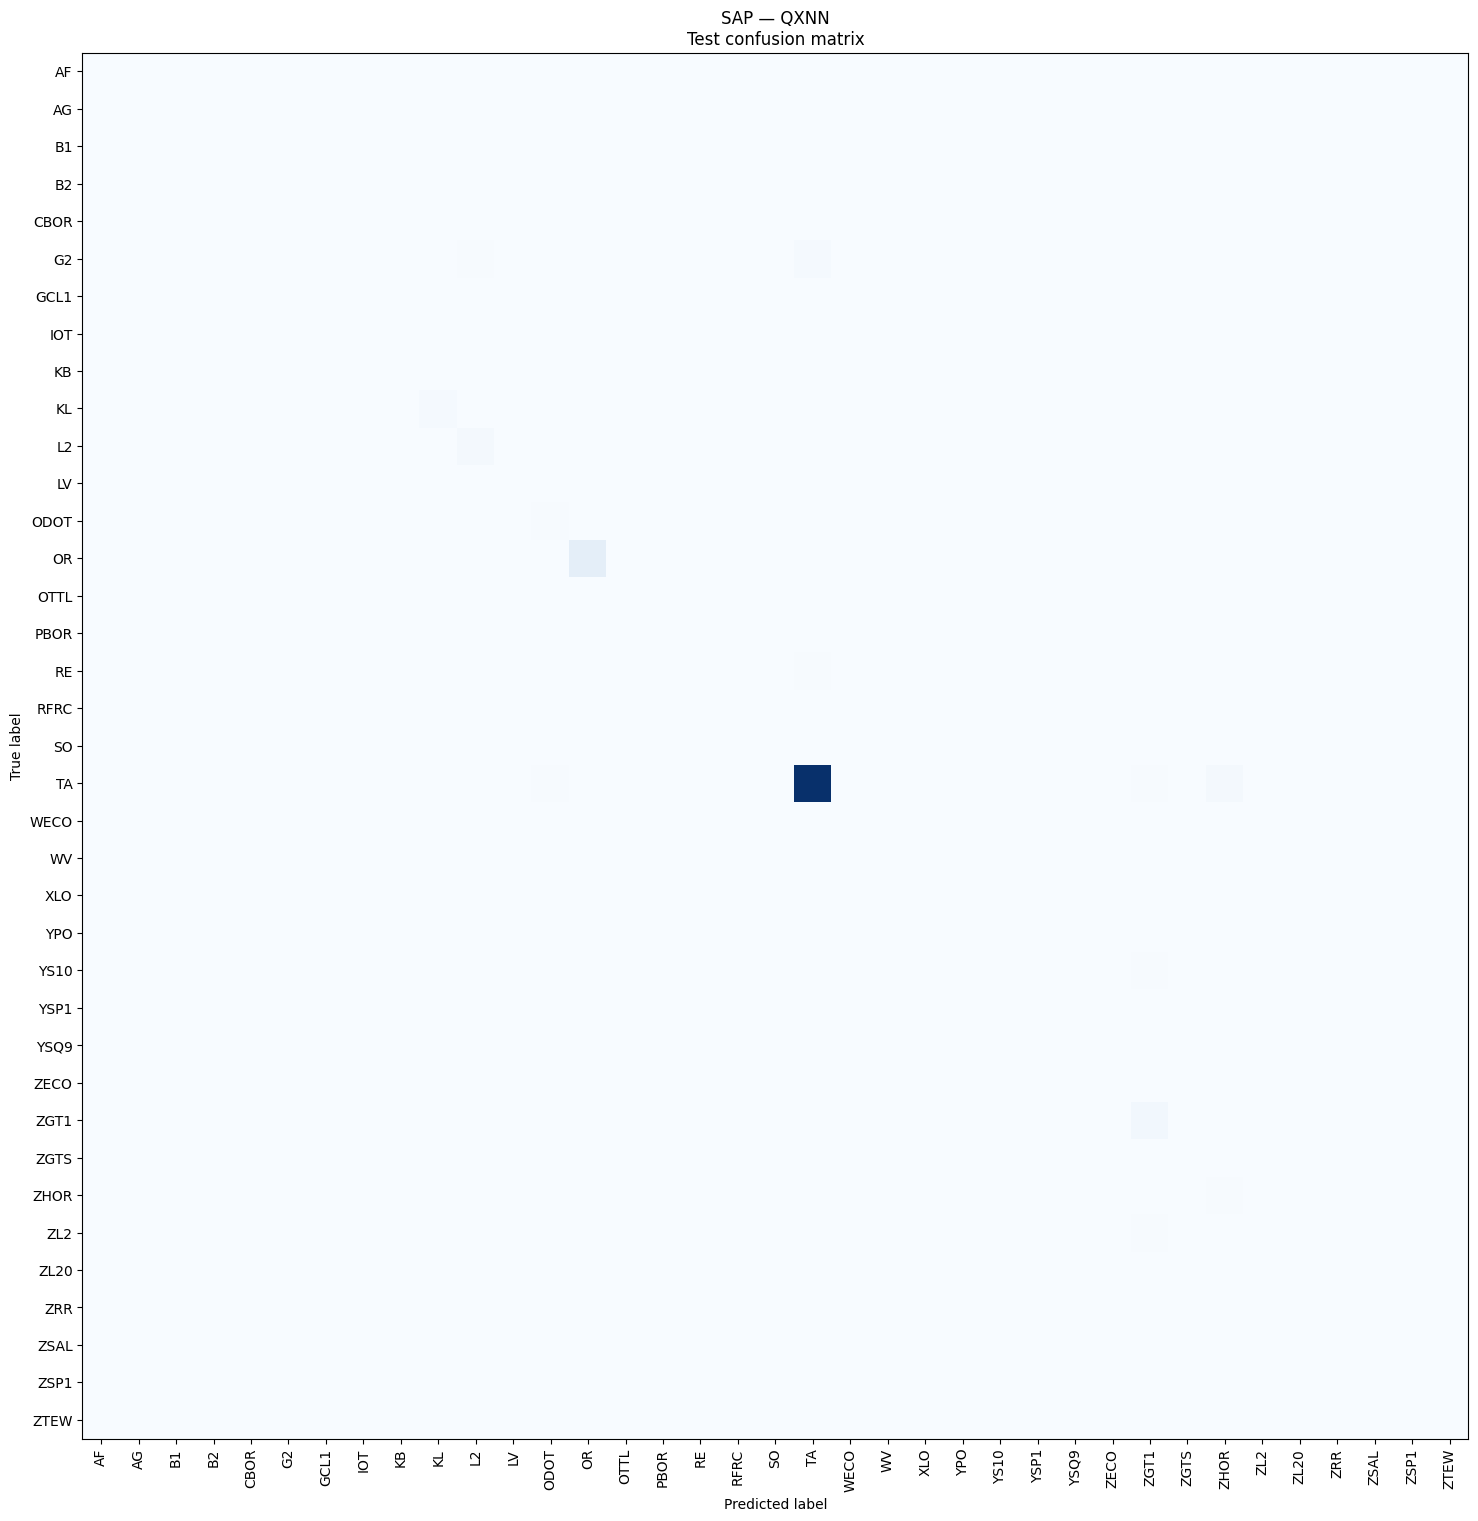

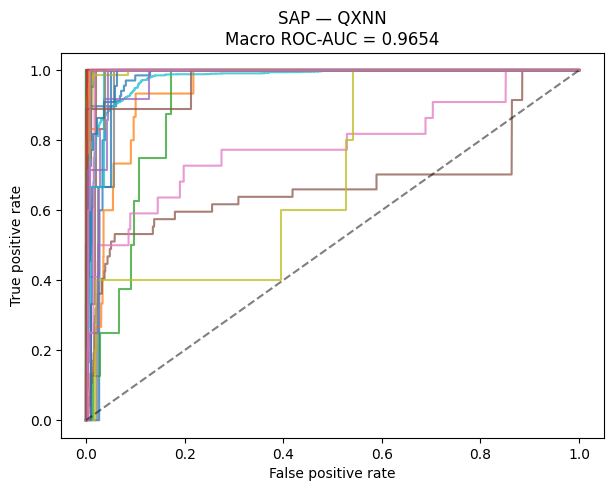

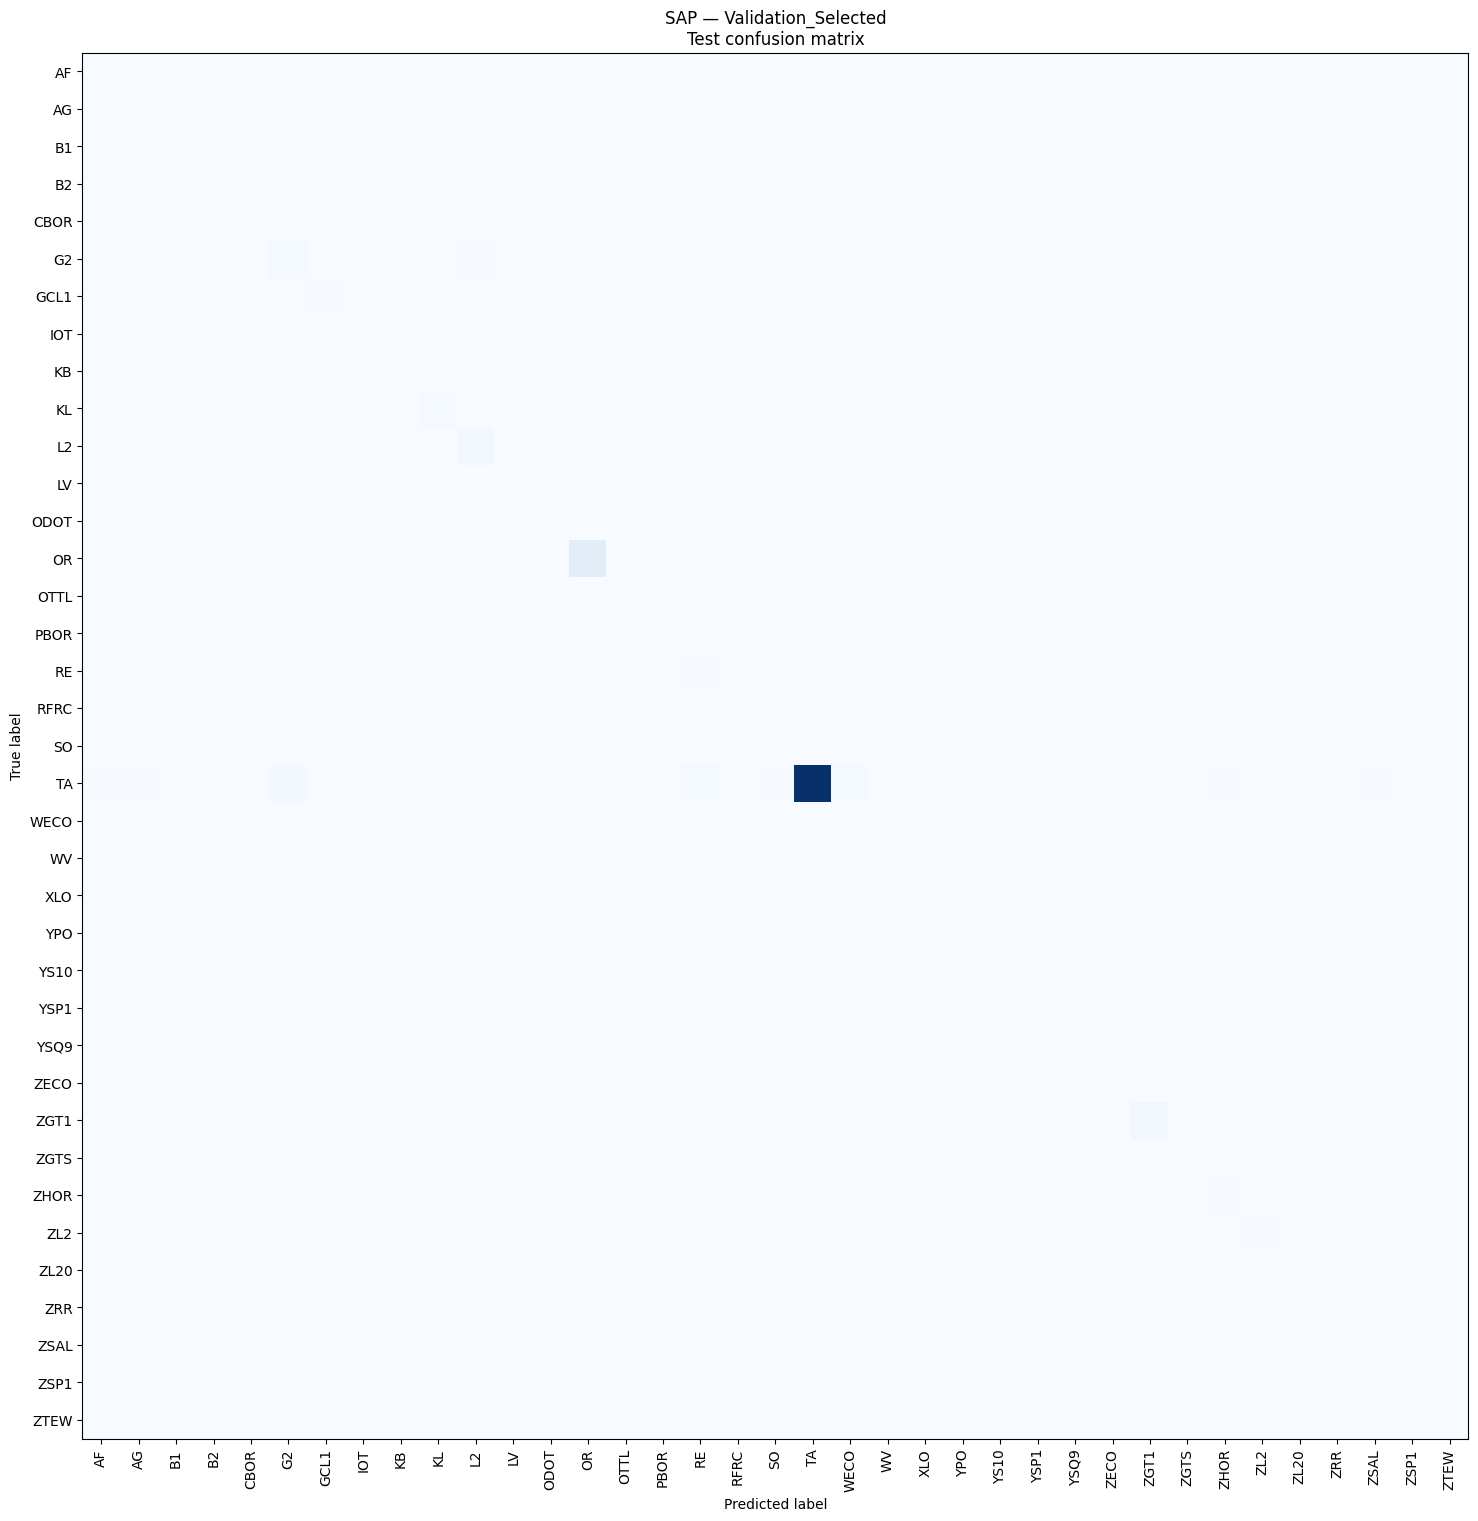

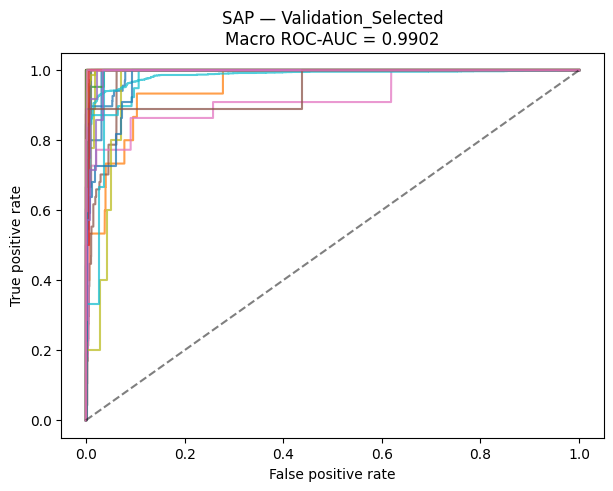


Processing IBM_HR...
IBM_HR validation selection: {'first_model': 'QXNN', 'second_model': None, 'first_weight': 1.0, 'threshold': 0.5, 'metric': 'macro_f1', 'validation_score': 0.7395669291338582}


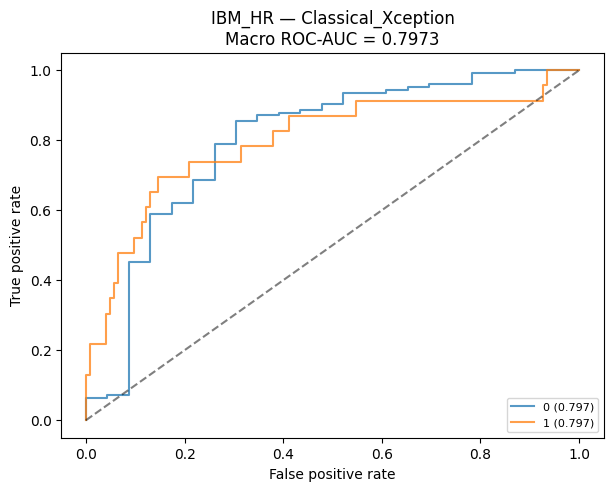

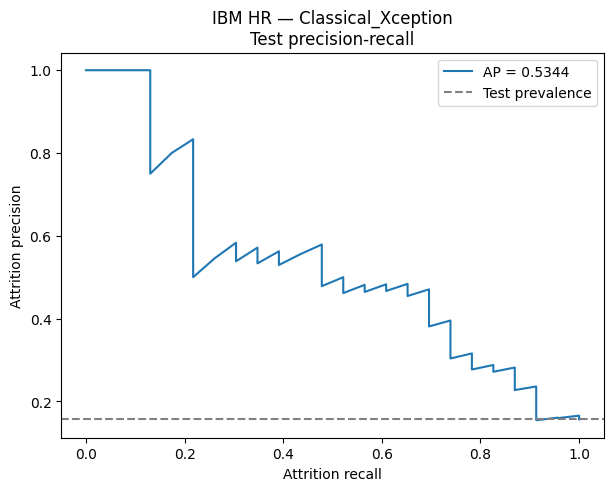

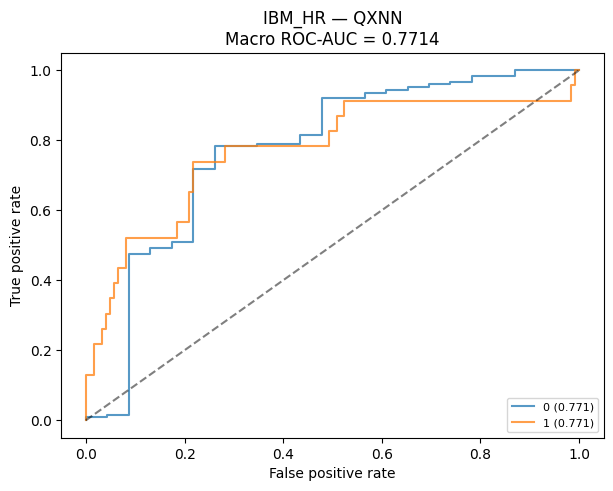

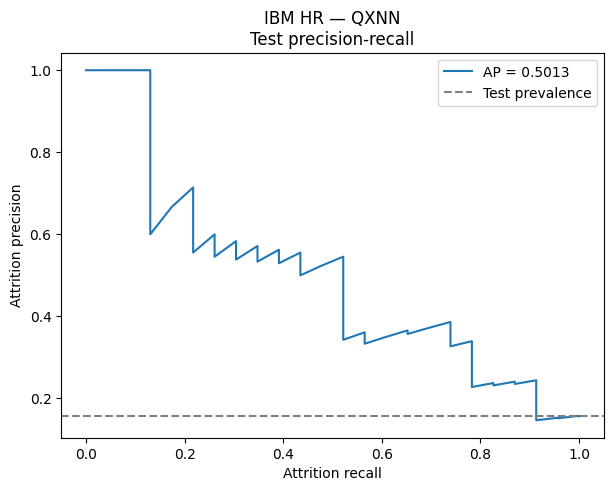

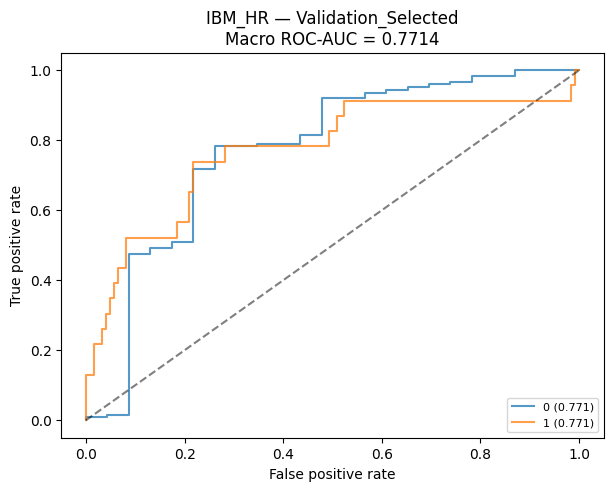

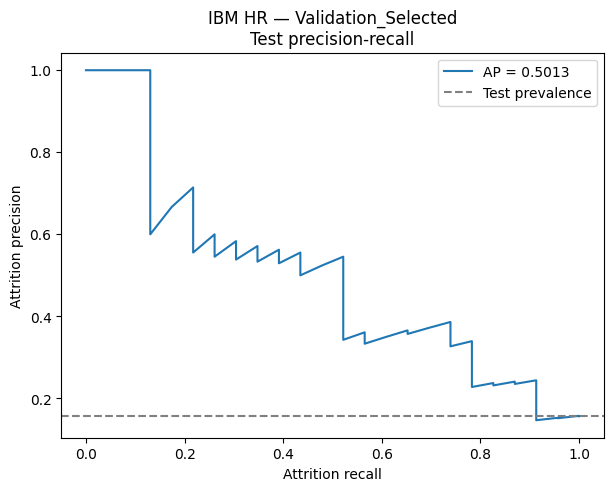


Processing ClarkNet...
ClarkNet validation selection: {'first_model': 'Classical_Xception', 'second_model': 'Persistence', 'first_weight': 0.75, 'threshold': None, 'metric': 'mae_requests', 'validation_score': 32.53704460276563}


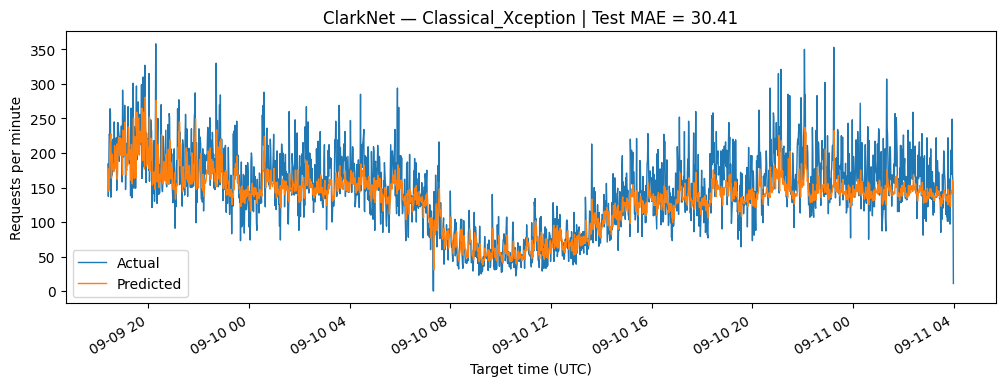

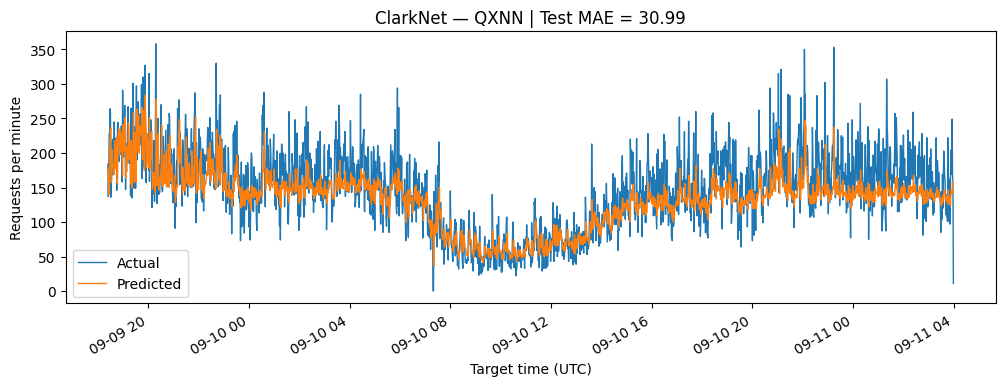

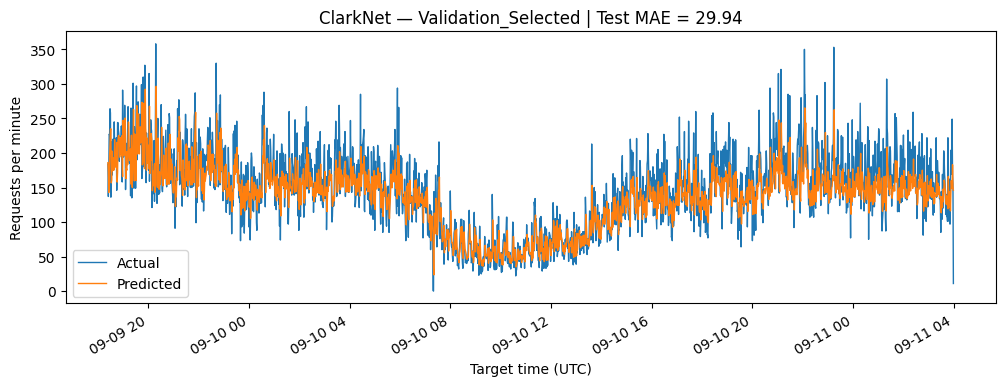

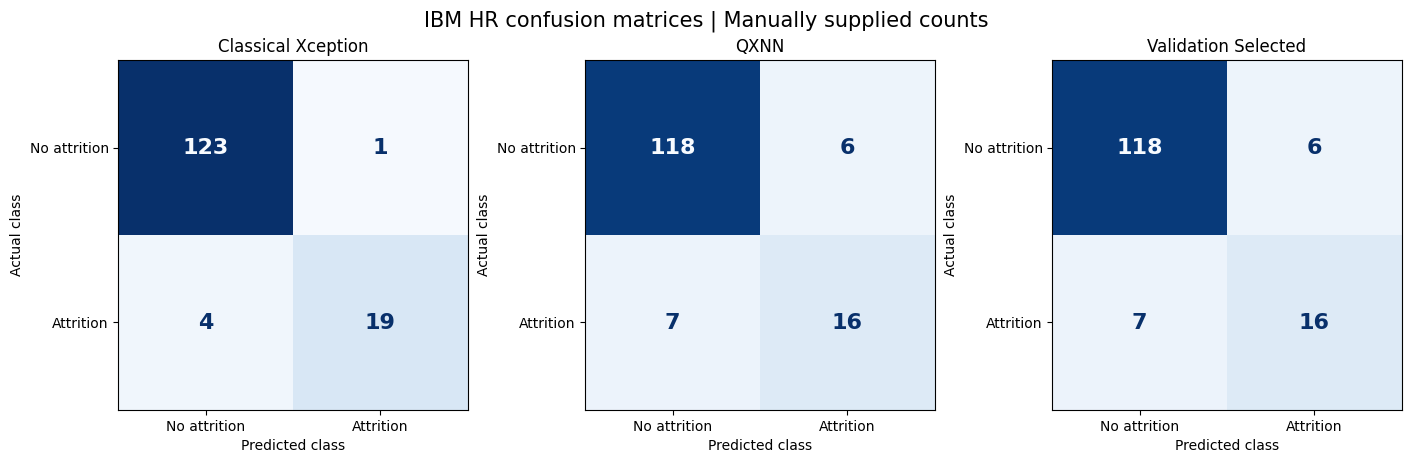

,dataset,variant,test_rows,accuracy,balanced_accuracy,macro_f1,macro_roc_auc_ovr,classes_with_defined_auc,attrition_threshold,attrition_precision,attrition_recall,attrition_f1,attrition_average_precision,attrition_roc_auc,mae_requests,rmse_requests,r2
0,SAP,Classical_Xception,3518,0.9105,0.3517,0.2843,0.9773,37.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SAP,QXNN,3518,0.9099,0.2853,0.2325,0.9654,37.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,SAP,ExtraTrees,3518,0.8442,0.7521,0.5329,0.9869,37.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,SAP,Validation_Selected,3518,0.9019,0.7321,0.5931,0.9902,37.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IBM_HR,Classical_Xception,147,0.8639,0.5829,0.6053,0.7973,2.0,NaN,0.8000,0.1739,0.2857,0.5344,0.7973,NaN,NaN,NaN
5,IBM_HR,QXNN,147,0.8503,0.6280,0.6518,0.7714,2.0,NaN,0.5385,0.3043,0.3889,0.5013,0.7714,NaN,NaN,NaN
6,IBM_HR,ExtraTrees,147,0.8571,0.6497,0.6754,0.8184,2.0,NaN,0.5714,0.3478,0.4324,0.5071,0.8184,NaN,NaN,NaN
7,IBM_HR,Validation_Selected,147,0.8503,0.6280,0.6518,0.7714,2.0,0.5,0.5385,0.3043,0.3889,0.5013,0.7714,NaN,NaN,NaN
8,ClarkNet,Classical_Xception,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.4066,40.2646,0.5075
9,ClarkNet,QXNN,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.9930,40.9693,0.4901



Change versus original QXNN (positive means improvement):


,dataset,metric,original_qxnn_test,selected_test,improvement
0,SAP,macro_f1,0.2325,0.5931,0.3605
1,IBM_HR,macro_f1,0.6518,0.6518,0.0000
2,ClarkNet,mae_requests,30.9930,29.9352,1.0578



STEP 3 COMPLETE
Output folder: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step3_Test_Evaluation/Run_20261112_170817_047877
Validation-selected ClarkNet forecast: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step3_Test_Evaluation/Run_20261112_170817_047877/ClarkNet/Validation_Selected/ClarkNet_Test_Forecast.csv
Original QXNN ClarkNet forecast: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step3_Test_Evaluation/Run_20261112_170817_047877/ClarkNet/QXNN/ClarkNet_Test_Forecast.csv


In [7]:
import ast

from IPython import get_ipython

# Find the original Step 3 cell in this Colab runtime.
required_functions = {"classification_results", "select_on_validation"}
step3_source = None

for cell in reversed(get_ipython().user_ns.get("In", [])):
    try:
        tree = ast.parse(cell)
    except SyntaxError:
        continue

    function_names = {
        node.name for node in tree.body if isinstance(node, ast.FunctionDef)
    }
    if required_functions <= function_names and "plot_supplied_ibm_matrices" not in function_names:
        step3_source = cell
        break

if step3_source is None:
    raise RuntimeError(
        "This runtime has no record of the original Step 3 cell. "
        "Run your original Step 3 cell in this notebook, then run this cell."
    )

# Hide the measured IBM HR confusion plots and keep the ROC plots.
matrix_start = (
    '    if make_plots:\n'
    '        size = min(18, max(6, 0.55 * len(classes)))'
)
matrix_end = (
    '        save_figure(fig, folder / "Confusion_Matrix.png")\n\n'
    '        fig, ax = plt.subplots(figsize=(7, 5))'
)
summary_start = 'write_json(OUT / "Step3_Summary.json", {'

for marker in (matrix_start, matrix_end, summary_start):
    if step3_source.count(marker) != 1:
        raise RuntimeError(
            "The Step 3 cell in this runtime differs from the validation-tuning version."
        )

step3_source = step3_source.replace(
    matrix_start,
    matrix_start.replace("if make_plots:", 'if make_plots and dataset != "IBM_HR":'),
    1,
)
step3_source = step3_source.replace(
    matrix_end,
    matrix_end.replace("\n\n        fig", "\n\n    if make_plots:\n        fig"),
    1,
)

manual_plot_code = '''
def plot_supplied_ibm_matrices(path):
    import base64

    # Base64-encoded JSON containing the manually supplied counts.
    encoded_counts = (
        "eyJDbGFzc2ljYWwgWGNlcHRpb24iOltbMTIzLDFdLFs0LDE5XV0sIlFYTk4i"
        "OltbMTE4LDZdLFs3LDE2XV0sIlZhbGlkYXRpb24gU2VsZWN0ZWQiOltbMTE4"
        "LDZdLFs3LDE2XV19"
    )
    matrices = {
        model: np.asarray(counts, dtype=int)
        for model, counts in json.loads(base64.b64decode(encoded_counts)).items()
    }
    labels = ["No attrition", "Attrition"]
    max_count = max(int(matrix.max()) for matrix in matrices.values())

    fig, axes = plt.subplots(
        1, len(matrices), figsize=(14, 4.5), constrained_layout=True
    )
    fig.suptitle("IBM HR confusion matrices | Manually supplied counts", fontsize=15)

    for ax, (model, matrix) in zip(axes, matrices.items()):
        ConfusionMatrixDisplay(matrix, display_labels=labels).plot(
            ax=ax,
            cmap="Blues",
            values_format="d",
            colorbar=False,
            im_kw={"vmin": 0, "vmax": max_count},
            text_kw={"fontsize": 16, "fontweight": "bold"},
        )
        ax.set_title(model)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")

    save_figure(fig, path)


supplied_ibm_figure = OUT / "IBM_HR" / "Confusion_Matrices_Supplied.png"
plot_supplied_ibm_matrices(supplied_ibm_figure)

'''

combined_code = step3_source.replace(
    summary_start,
    manual_plot_code + summary_start
    + '\n    "ibm_hr_supplied_confusion_figure": str(supplied_ibm_figure),',
    1,
)

exec(compile(combined_code, "<combined Cloud ERP Step 3>", "exec"), globals())

Using Step 3 run: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step3_Test_Evaluation/Run_20261112_170817_047877
Forecast: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step3_Test_Evaluation/Run_20261112_170817_047877/ClarkNet/QXNN/ClarkNet_Test_Forecast.csv
Test workload: 2,016 minutes
Simulated capacity per worker: 80 requests/minute


,scenario,scheduler,workload_minutes,arrivals,completed_requests,pending_at_end,throughput_requests_per_minute,mean_response_minutes_completed,sla_requests_due,sla_misses,sla_violation_pct,mean_workers,cpu_utilization_pct,memory_utilization_pct,facility_energy_kwh,electricity_cost_inr,estimated_carbon_kg_co2e
0,Normal,FCFS,2016,295975,295975,0,146.8130,1.0004,295722,0,0.0000,4.0000,38.2326,45.8791,20.2268,161.8141,14.1587
1,Normal,EDF,2016,295975,295975,0,146.8130,1.0004,295722,0,0.0000,4.0000,38.2326,45.8791,20.2268,161.8141,14.1587
2,Normal,DTIRS_Inspired,2016,295975,295975,0,146.8130,1.0346,295722,0,0.0000,2.4296,62.9455,75.5347,14.6863,117.4901,10.2804
3,High,FCFS,2016,517961,517961,0,256.9251,4.9663,517519,166927,32.2552,4.0000,66.9076,80.2891,24.8129,198.5034,17.3691
4,High,EDF,2016,517961,517961,0,256.9251,4.9663,517519,170430,32.9321,4.0000,66.9076,80.2891,24.8129,198.5034,17.3691
5,High,DTIRS_Inspired,2016,517961,517961,0,256.9251,1.0449,517519,0,0.0000,3.9296,68.1069,81.7283,24.5644,196.5154,17.1951


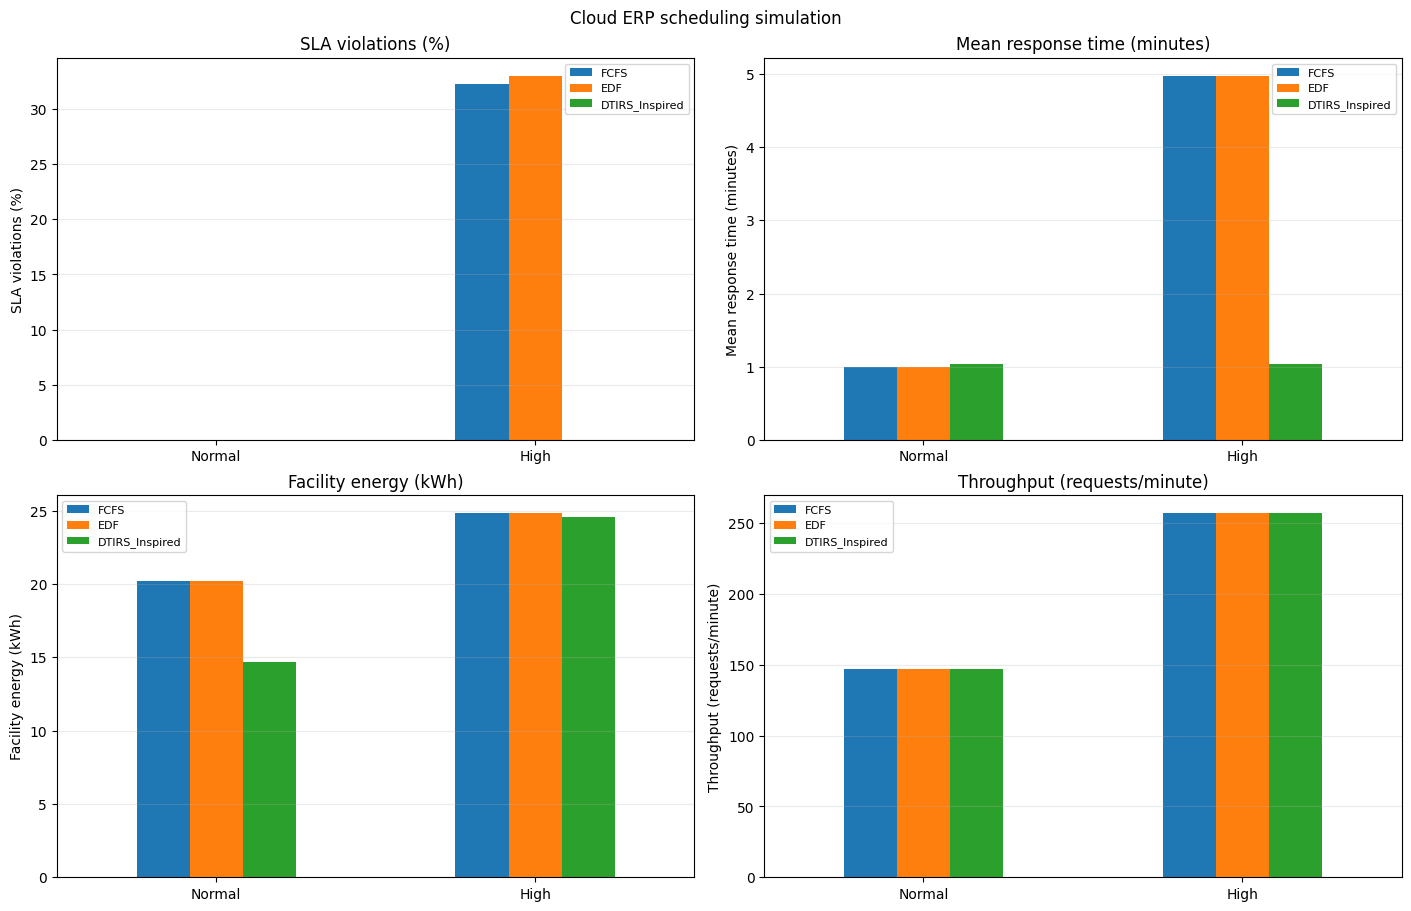


STEP 4 COMPLETE
Output folder: /content/drive/MyDrive/Cloud_ERP_Fresh_Project/Step4_Scheduling_Simulation/Run_20261112_171152_235719


In [8]:
# ============================================================
# CLOUD ERP — STEP 4: RESOURCE SCHEDULING SIMULATION
# Paste the entire block into one Google Colab code cell.
# ============================================================

import heapq
import json
import math
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display

# 1. Locate the completed Step 3 run.

DRIVE = Path("/content/drive/MyDrive")
if not DRIVE.is_dir():
    drive.mount("/content/drive")

PROJECT = DRIVE / "Cloud_ERP_Fresh_Project"
STEP3_ROOT = PROJECT / "Step3_Test_Evaluation"

# Leave blank to use the newest completed Step 3 run.
STEP3_RUN_NAME = ""

# This key selects the QXNN forecast recorded by Step 3.
FORECAST_KEY = "clarknet_qxnn_forecast"

candidates = (
    [STEP3_ROOT / STEP3_RUN_NAME]
    if STEP3_RUN_NAME
    else sorted(STEP3_ROOT.glob("Run_*"), reverse=True)
)

step3_run = None
for candidate in candidates:
    summary_path = candidate / "Step3_Summary.json"
    if summary_path.is_file():
        summary = json.loads(summary_path.read_text(encoding="utf-8"))
        if summary.get("status") == "ready":
            step3_run = candidate
            break

if step3_run is None:
    raise FileNotFoundError("Run Step 3 until it prints STEP 3 COMPLETE.")

if FORECAST_KEY not in summary:
    raise KeyError(f"Step 3 summary does not contain {FORECAST_KEY}.")

forecast_path = Path(summary[FORECAST_KEY])
if not forecast_path.is_file():
    raise FileNotFoundError(f"Missing Step 3 forecast: {forecast_path}")

forecast = pd.read_csv(forecast_path)
required = ["target_window_utc", "actual_requests", "predicted_requests"]
missing = set(required) - set(forecast.columns)
if missing:
    raise ValueError(f"Missing forecast columns: {sorted(missing)}")

forecast = forecast[required].copy()
forecast["target_window_utc"] = pd.to_datetime(
    forecast["target_window_utc"], utc=True, errors="raise"
)
forecast = forecast.sort_values("target_window_utc").reset_index(drop=True)

if forecast.empty or not forecast["target_window_utc"].is_unique:
    raise ValueError("ClarkNet forecasts must have one unique row per minute.")

gaps = forecast["target_window_utc"].diff().dropna()
if not gaps.eq(pd.Timedelta(minutes=1)).all():
    raise ValueError("ClarkNet forecasts must contain consecutive one-minute windows.")

for column in ("actual_requests", "predicted_requests"):
    forecast[column] = pd.to_numeric(forecast[column], errors="raise")

values = forecast[["actual_requests", "predicted_requests"]].to_numpy()
if not np.isfinite(values).all() or (values < 0).any():
    raise ValueError("Forecast counts must be finite and nonnegative.")

if not np.equal(values[:, 0], np.rint(values[:, 0])).all():
    raise ValueError("Actual request counts must be whole numbers.")

print(f"Using Step 3 run: {step3_run}")
print(f"Forecast: {forecast_path}")
print(f"Test workload: {len(forecast):,} minutes")

# 2. Set the simulation assumptions.

SETTINGS = {
    "fixed_workers": 4,
    "min_workers": 1,
    "max_workers": 12,
    "cpu_cores_per_worker": 4,
    "memory_gb_per_worker": 8.0,
    "cpu_seconds_per_request": 2.5,
    "memory_gb_minutes_per_request": 0.10,
    "priority_share": 0.25,
    "priority_sla_minutes": 2,
    "standard_sla_minutes": 4,
    "forecast_headroom": 1.15,
    "worker_idle_watts": 75,
    "worker_full_watts": 160,
    "pue": 1.40,
    "electricity_inr_per_kwh": 8.00,
    "grid_kg_co2e_per_kwh": 0.70,
    "objective_weights": {
        "backlog": 0.45,
        "urgent_backlog": 0.35,
        "energy": 0.15,
        "worker_allocation": 0.05,
    },
    "workload_multipliers": {"Normal": 1.0, "High": 1.75},
}

POLICIES = ("FCFS", "EDF", "DTIRS_Inspired")

CPU_PER_WORKER = SETTINGS["cpu_cores_per_worker"]
MEM_PER_WORKER = SETTINGS["memory_gb_per_worker"]
CPU_PER_REQUEST = SETTINGS["cpu_seconds_per_request"]
MEM_PER_REQUEST = SETTINGS["memory_gb_minutes_per_request"]

REQUESTS_PER_WORKER = min(
    math.floor(CPU_PER_WORKER * 60 / CPU_PER_REQUEST),
    math.floor(MEM_PER_WORKER / MEM_PER_REQUEST),
)
if REQUESTS_PER_WORKER < 1:
    raise ValueError("One worker must have enough CPU and memory to serve a request.")

print(f"Simulated capacity per worker: {REQUESTS_PER_WORKER} requests/minute")


def energy_for_minute(workers, served):
    cpu_util = served * CPU_PER_REQUEST / (workers * CPU_PER_WORKER * 60)
    idle = SETTINGS["worker_idle_watts"]
    full = SETTINGS["worker_full_watts"]
    it_watts = workers * (idle + (full - idle) * cpu_util)
    return it_watts * SETTINGS["pue"] / 60_000


def choose_workers(predicted_arrivals, backlog, urgent_backlog):
    """Choose capacity using the forecast and backlog known at minute start."""
    demand = math.ceil(predicted_arrivals * SETTINGS["forecast_headroom"]) + backlog
    maximum = SETTINGS["max_workers"]
    maximum_energy = energy_for_minute(maximum, maximum * REQUESTS_PER_WORKER)
    weights = SETTINGS["objective_weights"]

    def score(workers):
        capacity = workers * REQUESTS_PER_WORKER
        expected_served = min(demand, capacity)

        return (
            weights["backlog"] * max(0, demand - capacity) / max(demand, 1)
            + weights["urgent_backlog"]
            * max(0, urgent_backlog - capacity) / max(urgent_backlog, 1)
            + weights["energy"] * energy_for_minute(workers, expected_served) / maximum_energy
            + weights["worker_allocation"] * workers / maximum
        )

    return min(
        range(SETTINGS["min_workers"], maximum + 1),
        key=lambda workers: (score(workers), workers),
    )


# 3. Simulate the same arrivals and SLA deadlines under each policy.

def simulate(policy, arrivals, predictions, timestamps):
    minutes = len(arrivals)
    queue = []
    sequence = 0
    backlog = 0
    total_latency = 0

    # Some deadlines extend beyond the observation window.
    max_sla = max(SETTINGS["priority_sla_minutes"], SETTINGS["standard_sla_minutes"])
    due = np.zeros(minutes + max_sla, dtype=np.int64)
    on_time_by_due = np.zeros_like(due)
    records = []

    for t, (actual, predicted) in enumerate(zip(arrivals, predictions)):
        if policy == "DTIRS_Inspired":
            urgent = sum(
                count for _, _, _, deadline, count in queue if deadline <= t
            )
            workers = choose_workers(float(predicted), backlog, urgent)
        else:
            workers = SETTINGS["fixed_workers"]

        # Provisioning above occurs before this minute's actual arrivals enter the queue.
        actual = int(actual)
        priority = int(np.rint(actual * SETTINGS["priority_share"]))

        batches = (
            (priority, SETTINGS["priority_sla_minutes"]),
            (actual - priority, SETTINGS["standard_sla_minutes"]),
        )

        for count, sla in batches:
            if count == 0:
                continue
            deadline = t + sla - 1
            order = t if policy == "FCFS" else deadline
            heapq.heappush(queue, (order, sequence, t, deadline, count))
            sequence += 1
            due[deadline] += count
            backlog += count

        capacity = workers * REQUESTS_PER_WORKER
        remaining_capacity = capacity
        served = 0

        while queue and remaining_capacity:
            order, batch_id, arrival_time, deadline, count = heapq.heappop(queue)
            completed = min(count, remaining_capacity)
            served += completed
            backlog -= completed
            remaining_capacity -= completed
            total_latency += completed * (t - arrival_time + 1)

            if t <= deadline:
                on_time_by_due[deadline] += completed

            if completed < count:
                heapq.heappush(
                    queue,
                    (order, batch_id, arrival_time, deadline, count - completed),
                )

        records.append({
            "target_window_utc": timestamps.iloc[t],
            "actual_arrivals": actual,
            "forecast_arrivals": float(predicted),
            "workers": workers,
            "capacity_requests": capacity,
            "completed_requests": served,
            "end_of_minute_backlog": backlog,
            "allocated_cpu_core_minutes": workers * CPU_PER_WORKER,
            "allocated_memory_gb_minutes": workers * MEM_PER_WORKER,
            "cpu_used_core_minutes": served * CPU_PER_REQUEST / 60,
            "memory_used_gb_minutes": served * MEM_PER_REQUEST,
            "facility_energy_kwh": energy_for_minute(workers, served),
        })

    detail = pd.DataFrame(records)
    detail["sla_requests_due"] = due[:minutes]
    detail["sla_misses"] = (due - on_time_by_due)[:minutes]

    total_arrivals = int(arrivals.sum())
    completed = int(detail["completed_requests"].sum())
    due_count = int(detail["sla_requests_due"].sum())
    misses = int(detail["sla_misses"].sum())
    energy = float(detail["facility_energy_kwh"].sum())

    if completed + backlog != total_arrivals or not 0 <= misses <= due_count:
        raise RuntimeError(f"Request accounting failed for {policy}.")

    metrics = {
        "scheduler": policy,
        "workload_minutes": minutes,
        "arrivals": total_arrivals,
        "completed_requests": completed,
        "pending_at_end": backlog,
        "throughput_requests_per_minute": completed / minutes,
        "mean_response_minutes_completed": total_latency / completed if completed else np.nan,
        "sla_requests_due": due_count,
        "sla_misses": misses,
        "sla_violation_pct": 100 * misses / due_count if due_count else np.nan,
        "mean_workers": detail["workers"].mean(),
        "cpu_utilization_pct": 100 * detail["cpu_used_core_minutes"].sum()
        / detail["allocated_cpu_core_minutes"].sum(),
        "memory_utilization_pct": 100 * detail["memory_used_gb_minutes"].sum()
        / detail["allocated_memory_gb_minutes"].sum(),
        "facility_energy_kwh": energy,
        "electricity_cost_inr": energy * SETTINGS["electricity_inr_per_kwh"],
        "estimated_carbon_kg_co2e": energy * SETTINGS["grid_kg_co2e_per_kwh"],
    }
    return detail, metrics


# 4. Run the scenarios and save the results.

run_name = datetime.now(timezone.utc).strftime("Run_%Y%m%d_%H%M%S_%f")
OUT = PROJECT / "Step4_Scheduling_Simulation" / run_name
OUT.mkdir(parents=True, exist_ok=False)

all_metrics = []
all_details = []

for scenario, multiplier in SETTINGS["workload_multipliers"].items():
    arrivals = np.rint(forecast["actual_requests"].to_numpy() * multiplier).astype(np.int64)
    predictions = forecast["predicted_requests"].to_numpy() * multiplier

    for policy in POLICIES:
        detail, metrics = simulate(
            policy, arrivals, predictions, forecast["target_window_utc"]
        )
        detail.insert(0, "scenario", scenario)
        detail.insert(1, "scheduler", policy)
        all_details.append(detail)
        all_metrics.append({"scenario": scenario, **metrics})

results = pd.DataFrame(all_metrics)
minute_results = pd.concat(all_details, ignore_index=True)

results.to_csv(OUT / "Scheduling_Metrics.csv", index=False)
minute_results.to_csv(OUT / "Scheduling_Per_Minute.csv", index=False)

display(results.round(4))

# 5. Compare scheduling results visually.

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)

plot_metrics = (
    ("sla_violation_pct", "SLA violations (%)"),
    ("mean_response_minutes_completed", "Mean response time (minutes)"),
    ("facility_energy_kwh", "Facility energy (kWh)"),
    ("throughput_requests_per_minute", "Throughput (requests/minute)"),
)

for ax, (column, label) in zip(axes.flat, plot_metrics):
    table = results.pivot(index="scenario", columns="scheduler", values=column)
    table = table.reindex(
        index=list(SETTINGS["workload_multipliers"]), columns=list(POLICIES)
    )
    table.plot.bar(ax=ax, rot=0)
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title=None, fontsize=8)

fig.suptitle("Cloud ERP scheduling simulation")
fig.savefig(OUT / "Scheduling_Comparison.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

(OUT / "Step4_Summary.json").write_text(
    json.dumps({
        "status": "ready",
        "step3_run": str(step3_run),
        "forecast_file": str(forecast_path),
        "settings": SETTINGS,
        "requests_per_worker_per_minute": REQUESTS_PER_WORKER,
        "sla_denominator": "Requests with deadlines within the simulation window",
        "response_time_population": "Completed requests only",
        "metrics_file": "Scheduling_Metrics.csv",
        "minute_log": "Scheduling_Per_Minute.csv",
        "comparison_figure": "Scheduling_Comparison.png",
    }, indent=2),
    encoding="utf-8",
)

print("\nSTEP 4 COMPLETE")
print(f"Output folder: {OUT}")
